# Part 2: Exploratory Data Analysis and Visualization

**Project:** Semiconductor yield (Pass/Fail) prediction from sensor signals
**Input:** `sensor_cleaned.csv` (hand-off file from Part 1, Data Understanding and Cleaning)

The cleaned file uses **0 = Pass** and **1 = Fail** in the `Fail` column. Part 1 describes the raw label as -1 (Pass) and 1 (Fail), so the mapping was applied there.

## Research questions
1. Which sensors separate Pass from Fail, and how strongly?
2. Does the fail rate change over time, and is that change real or just uneven row counts?
3. How much of the sensor data is redundant?
4. Do extreme sensor values come with more failures?

## Phases
1. Setup and checks
2. Univariate EDA
3. Bivariate and statistical EDA (with multiple-testing correction)
4. Time analysis
5. Outlier analysis
6. Summary and implications for modelling

## Phase 1: Setup and checks

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)
ALPHA = 0.05

raw = pd.read_csv("sensor_cleaned.csv")
TARGET = "Fail"
FEATURES = [c for c in raw.columns if c not in ("Time", TARGET)]
raw.columns = [str(c) for c in raw.columns]
FEATURES = [str(c) for c in FEATURES]

# Check whether the file was already in time order before we sort it
time_parsed = pd.to_datetime(raw["Time"])
print("Already in time order:", time_parsed.is_monotonic_increasing)

df = raw.copy()
df["Time"] = time_parsed
df = df.sort_values("Time").reset_index(drop=True)

print("Rows:", len(df), "| Sensors:", len(FEATURES))
print("Time range:", df["Time"].min(), "to", df["Time"].max())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows (all columns):", int(df.duplicated().sum()))
print("Label values:", sorted(df[TARGET].unique()))
print("Fails:", int(df[TARGET].sum()), "| Fail rate:", round(df[TARGET].mean() * 100, 2), "%")

Already in time order: True
Rows: 1567 | Sensors: 269
Time range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00
Missing values: 0
Duplicate rows (all columns): 0
Label values: [np.int64(0), np.int64(1)]
Fails: 104 | Fail rate: 6.64 %



### EDA checklist: data types, preview, and summary statistics
Standard beginner checklist: data types, a preview of the rows, and a summary-statistics table. Shown here so the basics are on record before the analysis.


In [2]:

print("Data types:")
print(df.dtypes.value_counts().rename("count").to_string())
print("\nColumns that are not numeric:", [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])])
print("\nPreview (first 5 rows, first 8 columns):")
display(df.iloc[:5, :8])

summary = df[FEATURES].describe(percentiles=[0.25, 0.5, 0.75]).T[["mean", "std", "min", "50%", "max"]]
summary.columns = ["mean", "std", "min", "median", "max"]
print("\nSummary statistics for the first 10 sensors:")
display(summary.head(10).round(3))


Data types:
float64           269
datetime64[us]      1
int64               1

Columns that are not numeric: ['Time']

Preview (first 5 rows, first 8 columns):


,Time,0,1,2,3,4,6,7
0,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,97.6133,0.1242
1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,102.3433,0.1247
2,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,95.4878,0.1241
3,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,104.2367,0.1217
4,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.3967,0.1235



Summary statistics for the first 10 sensors:


,mean,std,min,median,max
0,3014.442,73.481,2743.240,3011.490,3356.350
1,2495.866,80.228,2158.750,2499.405,2846.440
2,2200.552,29.381,2060.660,2201.067,2315.267
3,1395.383,439.837,0.000,1285.214,3715.042
4,4.171,56.104,0.682,1.317,1114.537
6,101.116,6.209,82.131,101.512,129.252
7,0.122,0.009,0.000,0.122,0.129
8,1.463,0.074,1.191,1.462,1.656
9,-0.001,0.015,-0.053,-0.001,0.075
10,0.000,0.009,-0.035,0.000,0.053


## Phase 2: Univariate EDA
Target balance first, then the distributions of a sample of sensors. This first pass shows the target balance and the spread of all sensors. Individual sensor distributions are in the revisited section after Phase 3, which shows the 4 strongest sensors plus 4 random ones.

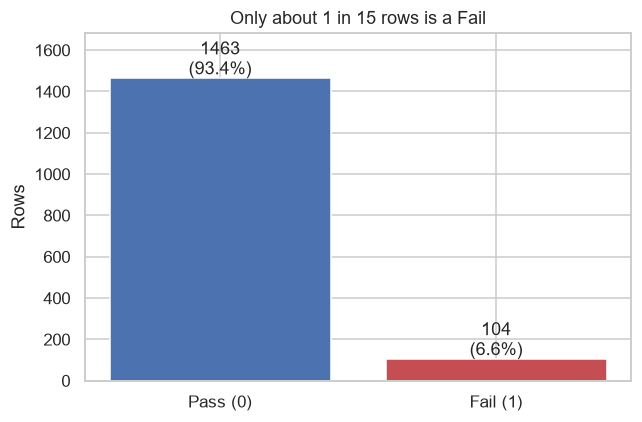

In [3]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Pass (0)", "Fail (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for b, n in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 20, f"{n}\n({n / counts.sum() * 100:.1f}%)", ha="center")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Only about 1 in 15 rows is a Fail")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()

Std dev range: 0.000104 to 6.55e+03
Sensors with |skew| > 2: 129 of 269


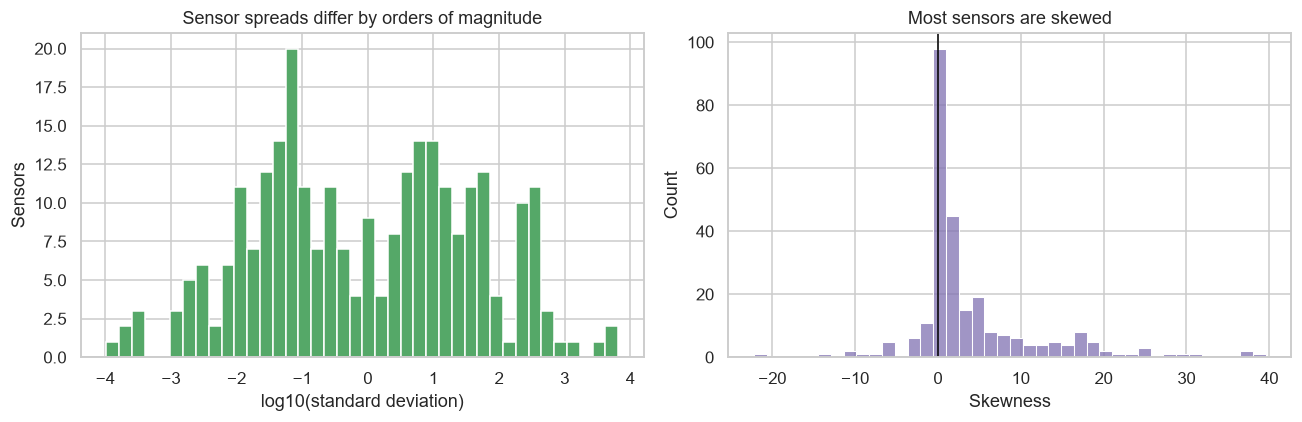

In [4]:
desc = df[FEATURES].describe().T
desc["skew"] = df[FEATURES].skew()
print("Std dev range:", f"{desc['std'].min():.3g}", "to", f"{desc['std'].max():.3g}")
print("Sensors with |skew| > 2:", int((desc['skew'].abs() > 2).sum()), "of", len(FEATURES))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(desc["std"].replace(0, np.nan).dropna()), bins=40, color="#55A868", edgecolor="white")
axes[0].set_xlabel("log10(standard deviation)")
axes[0].set_ylabel("Sensors")
axes[0].set_title("Sensor spreads differ by orders of magnitude")
sns.histplot(desc["skew"].dropna(), bins=40, color="#8172B2", ax=axes[1])
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("Skewness")
axes[1].set_title("Most sensors are skewed")
plt.tight_layout()
plt.show()

## Phase 3: Bivariate and statistical EDA
For every sensor: Welch t-test, Cohen's d, and a Benjamini-Hochberg (BH) adjusted p-value. With 269 tests, about 13 would pass p < 0.05 by chance, so BH is used to control the false discovery rate.

In [5]:
passed = df[df[TARGET] == 0]
failed = df[df[TARGET] == 1]

def bh_adjust(p):
    p = np.asarray(p)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(ranked, 1)
    return out

rows = []
for f in FEATURES:
    a, b = passed[f], failed[f]
    t_stat, p_val = stats.ttest_ind(b, a, equal_var=False)
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    d = (b.mean() - a.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    rows.append({"sensor": f, "cohens_d": d, "abs_d": abs(d), "p_value": p_val})

effects = pd.DataFrame(rows)
effects["q_value"] = bh_adjust(effects["p_value"].values)
effects = effects.sort_values("q_value").reset_index(drop=True)

print("Sensors tested:", len(effects))
print("p < 0.05 before correction:", int((effects['p_value'] < ALPHA).sum()))
print("q < 0.05 after BH correction:", int((effects['q_value'] < ALPHA).sum()))
print("|d| >= 0.5 (medium or larger):", int((effects['abs_d'] >= 0.5).sum()))
effects.head(15).round(4)

Sensors tested: 269
p < 0.05 before correction: 54
q < 0.05 after BH correction: 20
|d| >= 0.5 (medium or larger): 2


,sensor,cohens_d,abs_d,p_value,q_value
0,129,0.4763,0.4763,0.0000,0.0000
1,59,0.5915,0.5915,0.0000,0.0000
2,103,0.5715,0.5715,0.0000,0.0001
3,28,-0.4423,0.4423,0.0000,0.0012
4,125,-0.3684,0.3684,0.0001,0.0040
5,316,-0.3840,0.3840,0.0001,0.0040
6,130,0.3447,0.3447,0.0001,0.0054
7,122,-0.3465,0.3465,0.0002,0.0066
8,573,-0.2585,0.2585,0.0002,0.0074
9,124,0.3784,0.3784,0.0003,0.0084


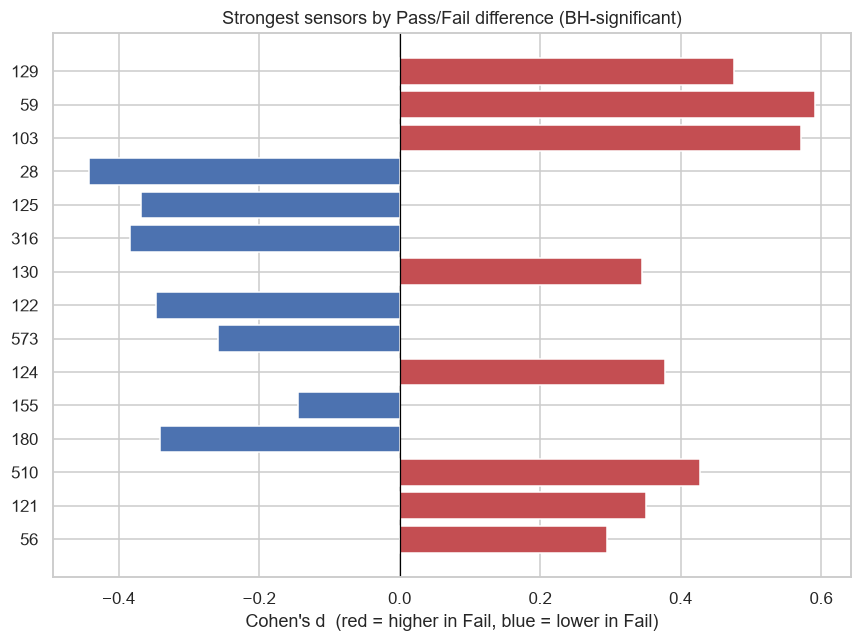

In [6]:
sig = effects[effects["q_value"] < ALPHA].head(15)
show = sig if len(sig) else effects.head(15)
colors = np.where(show["cohens_d"] > 0, "#C44E52", "#4C72B0")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(show["sensor"][::-1], show["cohens_d"][::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cohen's d  (red = higher in Fail, blue = lower in Fail)")
ax.set_title("Strongest sensors by Pass/Fail difference" + (" (BH-significant)" if len(sig) else " (none significant after BH)"))
plt.tight_layout()
plt.show()

In [7]:
# Redundancy: cluster sensors whose absolute correlation is above 0.9
corr = df[FEATURES].corr().abs()
dist = 1 - corr.values
np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method="average")
cluster_id = fcluster(Z, t=0.1, criterion="distance")  # |corr| >= 0.9 within a cluster
clusters = pd.DataFrame({"sensor": FEATURES, "cluster": cluster_id})
sizes = clusters.groupby("cluster")["sensor"].transform("size")
redundant = clusters[sizes > 1]

n_groups = redundant["cluster"].nunique()
print("Redundant groups (|corr| >= 0.9):", n_groups)
print("Sensors in those groups:", len(redundant))
print("Sensors you could drop keeping one per group:", len(redundant) - n_groups)

# Keep the sensor with the largest Pass/Fail effect in each group
effect_map = effects.set_index("sensor")["abs_d"]
redundant = redundant.assign(abs_d=redundant["sensor"].map(effect_map))
keep = redundant.sort_values("abs_d", ascending=False).groupby("cluster").head(1)["sensor"]
print("Representative sensors kept:", len(keep))

Redundant groups (|corr| >= 0.9): 19
Sensors in those groups: 39
Sensors you could drop keeping one per group: 20
Representative sensors kept: 19


## Phase 2 (revisited): Distributions of a sample of sensors
Now that Phase 3 has ranked the sensors, plot the 4 strongest and 4 random sensors. Box plots show overlap between Pass and Fail. Log scales are used for the skewed ones.

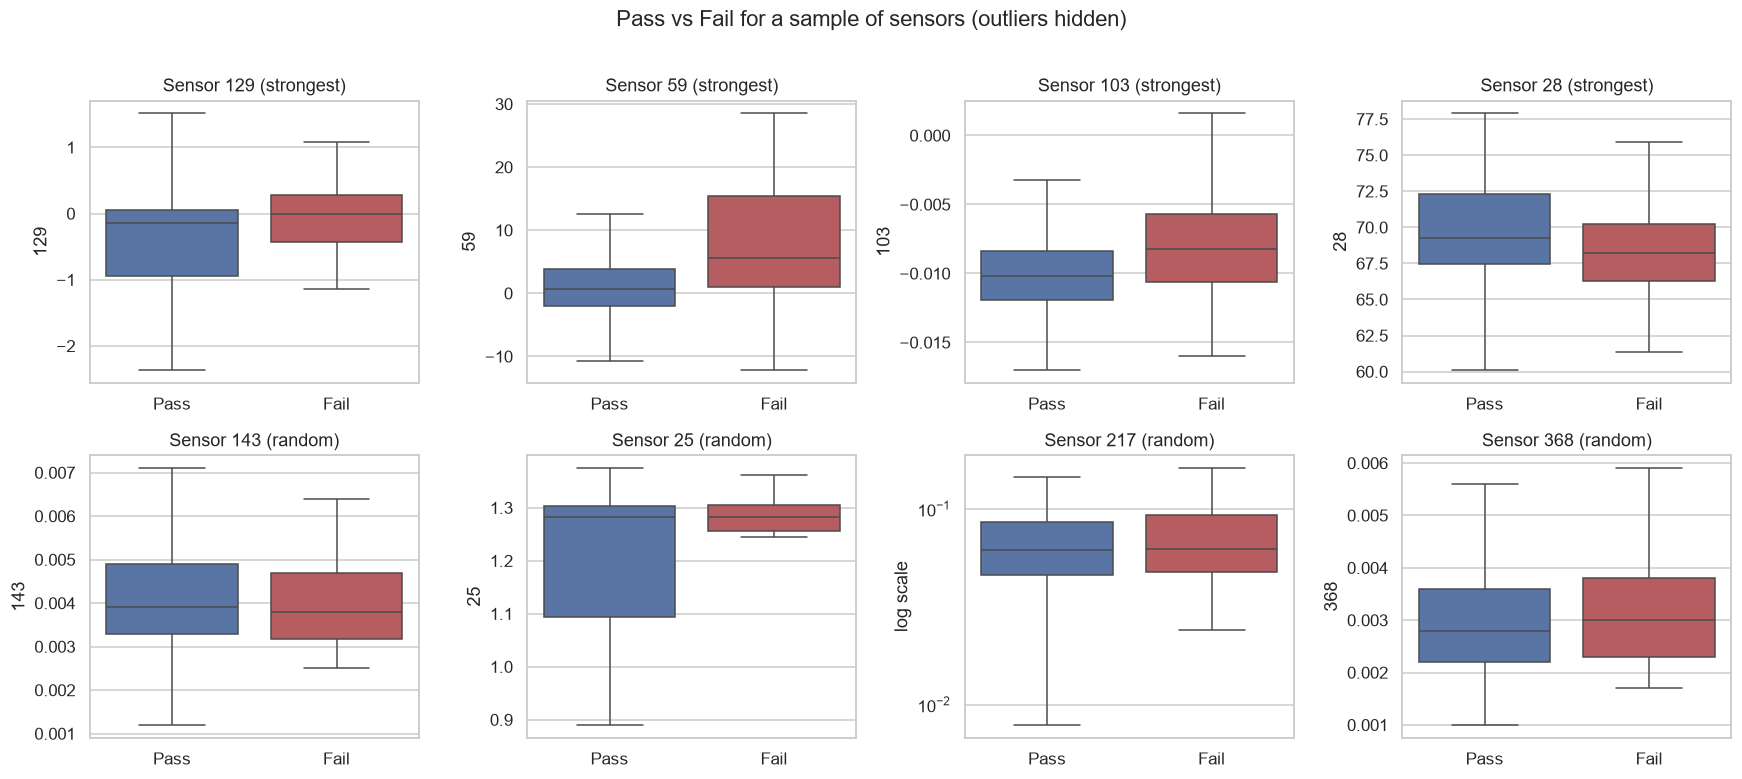

In [8]:
top4 = effects["sensor"].head(4).tolist()
rest = [f for f in FEATURES if f not in top4]
rand4 = list(RNG.choice(rest, size=4, replace=False))
sample = top4 + rand4

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), sample):
    sns.boxplot(data=df, x=TARGET, y=f, hue=TARGET, palette=["#4C72B0", "#C44E52"],
                legend=False, showfliers=False, ax=ax)
    ax.set_xticks([0, 1], ["Pass", "Fail"])
    ax.set_xlabel("")
    tag = "strongest" if f in top4 else "random"
    ax.set_title(f"Sensor {f} ({tag})")
    if abs(df[f].skew()) > 2 and (df[f] > 0).all():
        ax.set_yscale("log")
        ax.set_ylabel("log scale")
plt.suptitle("Pass vs Fail for a sample of sensors (outliers hidden)", y=1.01)
plt.tight_layout()
plt.show()

## Phase 4: Time analysis
Monthly fail rates with 95% Wilson intervals, so small or noisy months are visible. A chi-square test checks whether the fail rate differs across months.

         fails  rows  rate        lo        hi
month                                         
2008-07     14    63  22.2  0.137249  0.339125
2008-08     51   555   9.2  0.070583  0.118812
2008-09     17   590   2.9  0.018066  0.045657
2008-10     22   359   6.1  0.040814  0.091039

Chi-square across months: chi2=44.1, dof=3, p=1.4e-09


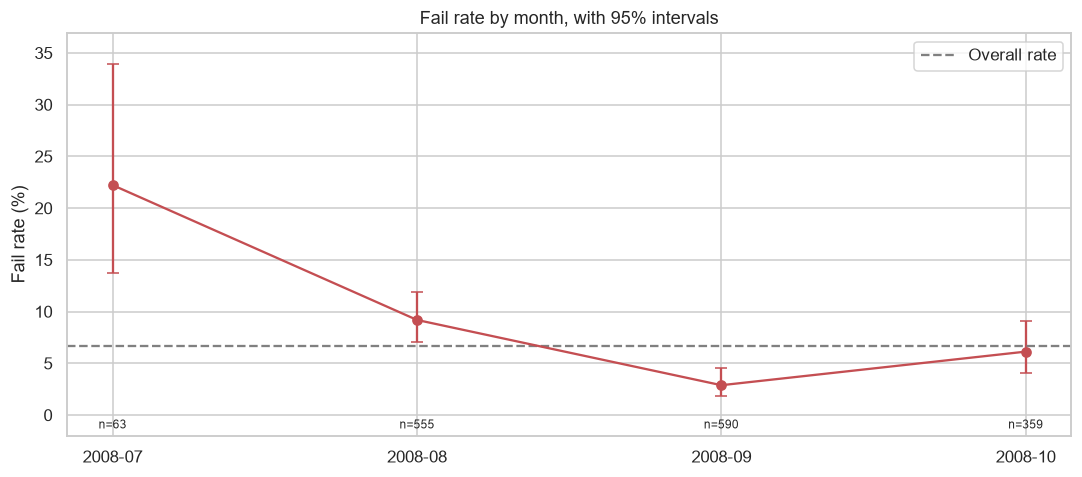

In [9]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

df["month"] = df["Time"].dt.to_period("M").astype(str)
monthly = df.groupby("month")[TARGET].agg(fails="sum", rows="size")
monthly["rate"] = monthly["fails"] / monthly["rows"]
ci = [wilson(k, n) for k, n in zip(monthly["fails"], monthly["rows"])]
monthly["lo"] = [c[0] for c in ci]
monthly["hi"] = [c[1] for c in ci]
print(monthly.assign(rate=(monthly['rate'] * 100).round(1)))

table = pd.crosstab(df["month"], df[TARGET])
chi2, p_chi, dof, _ = stats.chi2_contingency(table)
print(f"\nChi-square across months: chi2={chi2:.1f}, dof={dof}, p={p_chi:.2g}")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(monthly))
ax.errorbar(x, monthly["rate"] * 100,
            yerr=[(monthly["rate"] - monthly["lo"]) * 100, (monthly["hi"] - monthly["rate"]) * 100],
            fmt="o-", color="#C44E52", capsize=4)
ax.axhline(df[TARGET].mean() * 100, color="gray", ls="--", label="Overall rate")
for xi, n in zip(x, monthly["rows"]):
    ax.text(xi, -1.3, f"n={n}", ha="center", fontsize=8)
ax.set_xticks(x, monthly.index)
ax.set_ylabel("Fail rate (%)")
ax.set_ylim(-2, monthly["hi"].max() * 100 + 3)
ax.set_title("Fail rate by month, with 95% intervals")
ax.legend()
plt.tight_layout()
plt.show()

## Phase 5: Outlier analysis
For the 5 most significant sensors, a value is extreme if it is above Q3 + 3 x IQR. We compare fail rates in extreme rows against the rest with Fisher's exact test.

In [10]:
top5 = effects["sensor"].head(5).tolist()
extreme_any = pd.Series(False, index=df.index)
per_sensor = []
for f in top5:
    q1, q3 = df[f].quantile([0.25, 0.75])
    iqr = q3 - q1
    flag = df[f] > q3 + 3 * iqr
    extreme_any |= flag
    k_ext = int(df.loc[flag, TARGET].sum())
    n_ext = int(flag.sum())
    k_rest = int(df.loc[~flag, TARGET].sum())
    n_rest = int((~flag).sum())
    odds, p = stats.fisher_exact([[k_ext, n_ext - k_ext], [k_rest, n_rest - k_rest]])
    per_sensor.append({"sensor": f, "extreme_rows": n_ext,
                       "fail_rate_extreme_%": round(k_ext / n_ext * 100, 1) if n_ext else np.nan,
                       "fail_rate_rest_%": round(k_rest / n_rest * 100, 1),
                       "p_fisher": p})
print(pd.DataFrame(per_sensor).round(4))

k = int(df.loc[extreme_any, TARGET].sum())
n = int(extreme_any.sum())
print(f"\nAny extreme value in top 5: {n} rows, fail rate {k / n * 100:.1f}%"
      f" vs {df.loc[~extreme_any, TARGET].mean() * 100:.1f}% elsewhere")

  sensor  extreme_rows  fail_rate_extreme_%  fail_rate_rest_%  p_fisher
0    129             0                  NaN               6.6    1.0000
1     59            84                 16.7               6.1    0.0008
2    103             2                 50.0               6.6    0.1284
3     28             0                  NaN               6.6    1.0000
4    125             1                  0.0               6.6    1.0000

Any extreme value in top 5: 87 rows, fail rate 17.2% vs 6.0% elsewhere


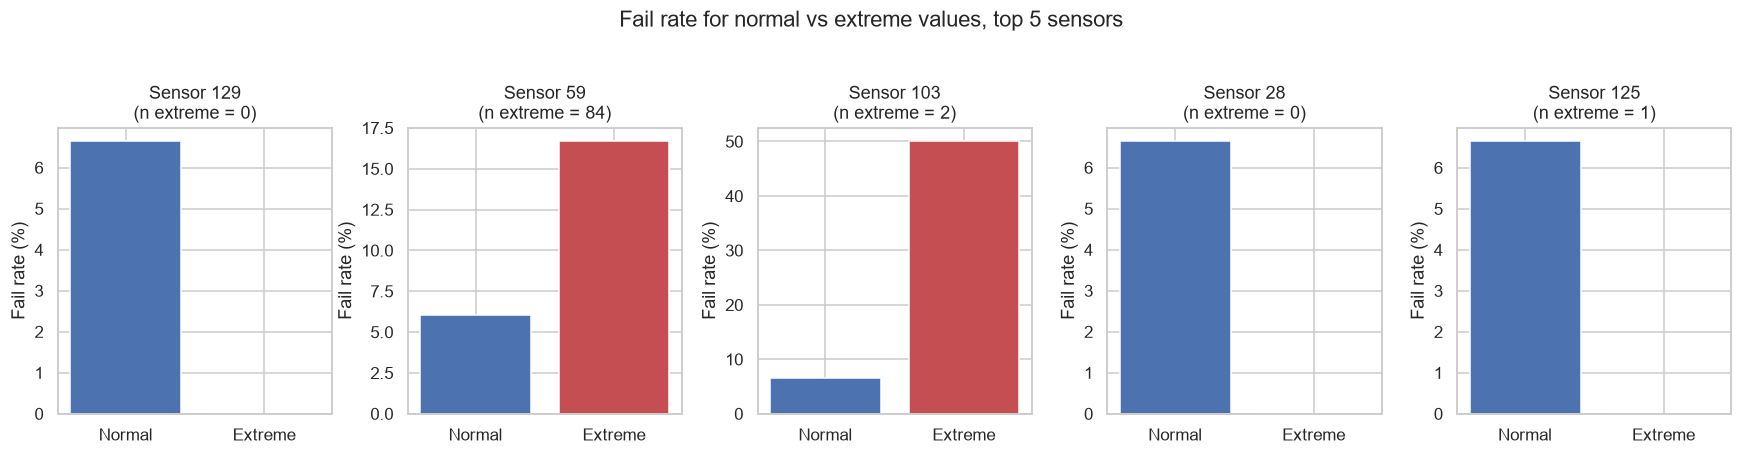

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharey=False)
for ax, f in zip(axes, top5):
    q1, q3 = df[f].quantile([0.25, 0.75])
    fence = q3 + 3 * (q3 - q1)
    flag = df[f] > fence
    rates = [df.loc[~flag, TARGET].mean() * 100, df.loc[flag, TARGET].mean() * 100 if flag.any() else 0]
    ax.bar(["Normal", "Extreme"], rates, color=["#4C72B0", "#C44E52"])
    ax.set_title(f"Sensor {f}\n(n extreme = {int(flag.sum())})")
    ax.set_ylabel("Fail rate (%)")
plt.suptitle("Fail rate for normal vs extreme values, top 5 sensors", y=1.03)
plt.tight_layout()
plt.show()

## Phase 6: Summary of my part (EDA and visualization)

**Data checked:** 1,567 wafers, 269 sensors, no missing values, no duplicate rows. 104 fails (6.6%).

**Findings**
* **Which sensors separate Pass from Fail:** only sensors 59 and 103 show a medium-or-larger difference. 20 sensors stay significant after correcting for multiple testing. Effects are small, so no single sensor predicts Fail well.
* **Does the fail rate change over time:** yes. July 22.2%, August 9.2%, September 2.9%, October 6.1% (chi-square p = 1.4e-9). July has only 63 wafers, so its rate is uncertain.
* **Redundancy:** 19 groups of sensors (correlation of 0.9 or more) involve 39 sensors. Keeping one per group drops 20 sensors.
* **Extreme values:** for sensor 59, readings above Q3 + 3 x IQR fail at 16.7%, against 6.1% otherwise (p = 0.0008). The sensors were picked partly for their Pass/Fail difference, so this is a lead to test on new data.

**Hand-off to the team**
* Sensors vary in scale by orders of magnitude, and many are skewed: scale before modelling.
* Keep one sensor per redundant group (the one with the largest Pass/Fail difference).
* The fail rate changes over time: use a time-based split, not a random one.
* Only 6.6% of wafers fail: use class weights, and judge models by recall and PR AUC, not accuracy.
